# 🎓 Mashinali o'qitish asosida talabalar o'zlashtirish ko'rsatkichini tahlil qilish

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gosanjar/talaba-ozlashtirish-ml/blob/main/notebook/talaba_ozlashtirish_ML.ipynb)

Bu notebook web tizimdagi modellar **qanday qurilganini** bosqichma-bosqich ko'rsatadi: ma'lumot qayerdan keladi, qanday qayta ishlanadi, qaysi algoritmlar sinaladi, eng yaxshisi qanday tanlanadi va aniqlik qanday oshiriladi.

**Ma'lumot:** 1500 talaba, 3 fakultet, 6 yo'nalish, 48 guruh (1–4 kurs), 34 fan, 9000 ta "talaba × fan" bahosi.

| # | Vazifa | Natija | Algoritmlar |
|---|---|---|---|
| 1 | **Regressiya** | Semestr yakuniy o'rtacha bali (0–100) | Ridge, Random Forest, HistGradientBoosting, XGBoost, Stacking |
| 2a | **Klassifikatsiya** | A'lo / Yaxshi / Qoniqarli / Qoniqarsiz | Logistik regressiya, RF, HGB, XGBoost, Soft-voting |
| 2b | **Klassifikatsiya** | O'tadi / O'tmaydi (kamida 1 fandan qarz) | xuddi shular |
| 2c | **Klassifikatsiya** | Chetlashtirish xavfi (3+ fandan qarz) | xuddi shular |
| 3 | **Fan darajasidagi model** | Har bir fan bo'yicha yakuniy ball va qarz ehtimoli | XGBoost + GroupKFold |
| 4 | **Klasterlash** | "Xavf guruhi", "Faol, lekin bahosi past" va h.k. | K-Means + PCA, Silhouette |
| 5 | **Anomaliyalar** | G'ayrioddiy profillar | Isolation Forest |
| 6 | **Izohlash** | Nima uchun model shunday dedi? | SHAP |

**Colab'da ishlatish:** `Runtime → Run all`. Dataset GitHub'dan avtomatik yuklanadi (~2–3 daqiqa ishlaydi).

In [1]:
%pip install -q xgboost shap

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json, os, time, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, shap
from scipy.stats import norm
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, StratifiedKFold, GroupKFold, cross_val_predict, RandomizedSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge, RidgeCV, LinearRegression, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor,
                              HistGradientBoostingClassifier, StackingRegressor, VotingClassifier, IsolationForest)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_absolute_error, r2_score, accuracy_score, f1_score, roc_auc_score, recall_score,
                             confusion_matrix, silhouette_score, roc_curve)
from xgboost import XGBRegressor, XGBClassifier
SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)

## 1. Ma'lumotlarni yuklash

Dataset 4 qismdan iborat (relyatsion tuzilma, HEMIS'ga o'xshash):

| Fayl | Mazmuni |
|---|---|
| `talabalar.csv` | 1 qator = 1 talaba: tuzilma (fakultet, yo'nalish, guruh, kurs), ijtimoiy-iqtisodiy (to'lov, kontrakt qarzi, ishlaydi, yashash), davomat (NB sababli/sababsiz), faollik (topshiriqlar %, LMS, kutubxona, mustaqil ta'lim), oldingi natijalar |
| `baholar.csv` | 1 qator = talaba × fan: joriy, oraliq va yakuniy nazorat (0–100). Yakuniy 15% talabada hali ma'lum emas — aynan shularni bashorat qilamiz |
| `fanlar.csv` | Fan nomi, kredit, baholash tizimi |
| `baholash_tizimlari.json` | 5 baholik, ECTS, GPA: chegaralar va o'tish bali |

> ⚠️ Ma'lumotlar real qonuniyatlar asosida **sun'iy yaratilgan** (yashirin omillar: qobiliyat, motivatsiya, ijtimoiy yuk). Haqiqiy tadqiqotda xuddi shu ustunli HEMIS eksporti bilan almashtiring.

In [3]:
BASE = "https://raw.githubusercontent.com/gosanjar/talaba-ozlashtirish-ml/main/dataset/"
def read(name):
    for p in (f"dataset/{name}", f"../dataset/{name}", name):      # lokal nusxa bo'lsa — o'shani
        if os.path.exists(p): return p
    return BASE + name
talabalar = pd.read_csv(read("talabalar.csv"))
baholar = pd.read_csv(read("baholar.csv"))
fanlar = pd.read_csv(read("fanlar.csv"))
src = read("baholash_tizimlari.json")
tizimlar = json.load(open(src)) if os.path.exists(src) else pd.read_json(src).to_dict("records")
print(f"Talabalar: {len(talabalar)}, baholar: {len(baholar)}, fanlar: {len(fanlar)}")
talabalar.head()

Talabalar: 1500, baholar: 9000, fanlar: 34


,talaba_id,fio,fakultet,yonalish_kod,yonalish,guruh,kurs,jinsi,hudud,tolov,...,yol_vaqti,kirish_bali,oldingi_ball,oldingi_qarzlar,nb_sababli,nb_sababsiz,topshiriq,lms_kirish,kutubxona,mustaqil_soat
0,1,Sharipova Hilola,Dasturiy injiniring fakulteti,SI,Sun'iy intellekt,SI24-2,3,Ayol,Toshkent sh.,Kontrakt,...,19.0,122.1,60.8,0.0,0.0,26.0,64.0,11.0,0.0,4.8
1,2,Rahimov Jahongir,Dasturiy injiniring fakulteti,DI,Dasturiy injiniring,DI24-1,3,Erkak,Toshkent sh.,Grant,...,18.0,148.3,83.8,0.0,10.0,36.0,51.0,16.0,4.0,0.6
2,3,Valiyev Ulug'bek,Dasturiy injiniring fakulteti,DI,Dasturiy injiniring,DI26-2,1,Erkak,Toshkent vil.,Kontrakt,...,30.0,138.2,65.3,0.0,4.0,6.0,91.0,32.0,1.0,11.4
3,4,Qosimova Dildora,Raqamli iqtisodiyot fakulteti,RI,Raqamli iqtisodiyot,RI25-2,2,Ayol,Toshkent sh.,Kontrakt,...,5.0,105.7,54.9,1.0,8.0,20.0,46.0,20.0,3.0,0.0
4,5,Mirzayeva Marjona,Kompyuter injiniringi fakulteti,KI,Kompyuter injiniringi,KI25-2,2,Ayol,Toshkent vil.,Kontrakt,...,22.0,120.9,62.3,0.0,8.0,4.0,83.0,15.0,1.0,10.8


In [4]:
baholar.head(8)

,talaba_id,fan_id,fan,kredit,tizim_id,joriy,oraliq,yakuniy
0,1,13,Falsafa,5,1,70.0,69.0,74.0
1,1,25,Kompyuter ko'rish,5,1,57.0,67.0,59.0
2,1,34,Ma'lumotlar tahlili,6,1,60.0,57.0,52.0
3,1,23,Mashinali o'qitish,4,1,63.0,49.0,54.0
4,1,12,Operatsion tizimlar,6,1,52.0,56.0,58.0
5,1,24,Sun'iy intellekt asoslari,5,1,57.0,61.0,62.0
6,2,20,Dasturiy ta'minot muhandisligi,5,1,86.0,80.0,75.0
7,2,13,Falsafa,5,1,85.0,93.0,86.0


In [5]:
# Baholash tizimi: har bir fanning o'tish chegarasi va umumiy toifalar (5 baholik tizim)
TIZIM = {t["id"]: sorted(t["chegaralar"], key=lambda c: -c["min"]) for t in tizimlar}
PASS_MIN = {tid: min(c["min"] for c in ch if c["otish"]) for tid, ch in TIZIM.items()}
FAOL = TIZIM[1]
TOIFA = [c["nomi"] for c in reversed(FAOL)]                     # pastdan yuqoriga
def toifa_idx(b): return max(i for i, c in enumerate(reversed(FAOL)) if b >= c["min"])
for t in tizimlar: print(t["nomi"], "→", ", ".join(f'{c["min"]}+ {c["baho"]}' for c in TIZIM[t["id"]]), "| o'tish:", PASS_MIN[t["id"]])

5 baholik tizim (100 ball) → 86+ 5, 71+ 4, 55+ 3, 0+ 2 | o'tish: 55
ECTS (A–F) → 90+ A, 80+ B, 70+ C, 60+ D, 50+ E, 0+ F | o'tish: 50
GPA 4.0 → 90+ 4.0, 80+ 3.0, 70+ 2.0, 60+ 1.0, 0+ 0.0 | o'tish: 60


## 2. Razvedka tahlili (EDA)

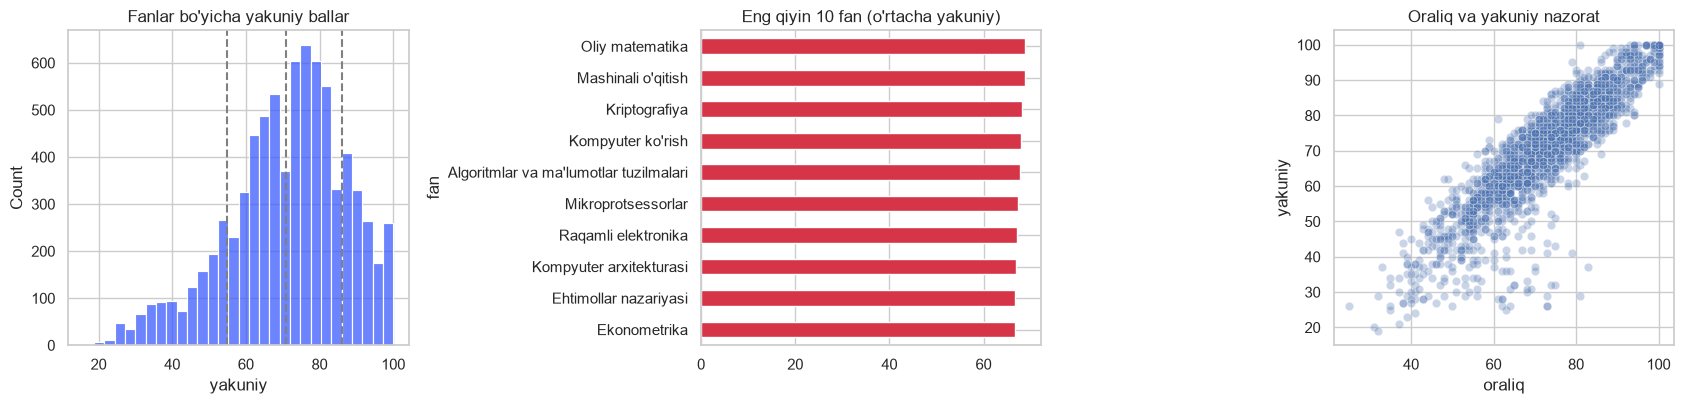

In [6]:
g = baholar.copy(); g["pass_min"] = g["tizim_id"].map(PASS_MIN)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(g["yakuniy"].dropna(), bins=30, ax=ax[0], color="#3b5bfd"); ax[0].set_title("Fanlar bo'yicha yakuniy ballar")
for c in FAOL[:-1]: ax[0].axvline(c["min"], ls="--", c="gray")
fan_ort = g.groupby("fan")["yakuniy"].mean().sort_values()
fan_ort.head(10).plot.barh(ax=ax[1], color="#d63447"); ax[1].set_title("Eng qiyin 10 fan (o'rtacha yakuniy)")
sns.scatterplot(data=g.sample(2500, random_state=1), x="oraliq", y="yakuniy", alpha=.3, ax=ax[2]); ax[2].set_title("Oraliq va yakuniy nazorat")
plt.tight_layout(); plt.show()

## 3. Belgilarni tayyorlash (feature engineering)

Model **talaba darajasida** ishlaydi. Har talabaning fanlari bo'yicha baholar agregatlanadi va yangi (hosila) belgilar yasaladi:

- **Agregatlar:** joriy va oraliq o'rtachasi, eng past/yuqori oraliq, fanlar orasidagi tafovut, oraliqdan o'tmagan fanlar soni.
- **Hosila belgilar:** `trend` (oraliq − oldingi semestr), `joriy_oraliq_farq`, `nb_jami`, `ish_yuki` (20 soatdan ortiq ish), `faollik` indeksi, `nb_limit` (sababsiz NB ≥ 36).
- **Maqsad (target):** kredit bilan tortilgan yakuniy o'rtacha. Faqat barcha fanlari yakunlangan talabalar uchun hisoblanadi.
- **Qarzlar soni:** yakuniy < o'tish chegarasi bo'lgan fanlar.

In [7]:
agg = g.groupby("talaba_id").agg(joriy_ortacha=("joriy", "mean"), oraliq_ortacha=("oraliq", "mean"), oraliq_min=("oraliq", "min"),
                                 oraliq_max=("oraliq", "max"), oraliq_std=("oraliq", "std"), fanlar_soni=("fan_id", "count"))
agg["past_fanlar"] = (g["oraliq"] < g["pass_min"]).groupby(g["talaba_id"]).sum()
known = g.groupby("talaba_id")["yakuniy"].apply(lambda s: s.notna().all())
gk = g[g["talaba_id"].isin(known[known].index)]
w = gk["kredit"]
agg["yakuniy_ortacha"] = (gk["yakuniy"] * w).groupby(gk["talaba_id"]).sum() / w.groupby(gk["talaba_id"]).sum()
agg["qarz_soni"] = (gk["yakuniy"] < gk["pass_min"]).groupby(gk["talaba_id"]).sum()

S = talabalar.merge(agg.reset_index(), on="talaba_id", how="left")
S["trend"] = S["oraliq_ortacha"] - S["oldingi_ball"]
S["joriy_oraliq_farq"] = S["joriy_ortacha"] - S["oraliq_ortacha"]
S["nb_jami"] = S["nb_sababsiz"] + S["nb_sababli"]
S["ish_yuki"] = (S["ish_soati"] - 20).clip(lower=0)
S["faollik"] = S["topshiriq"] / 100 + np.log1p(S["lms_kirish"]) / 5 + S["mustaqil_soat"] / 20 + S["kutubxona"] / 10
S["nb_limit"] = (S["nb_sababsiz"] >= 36).astype(int)

NUM_BASE = ["kurs", "yosh", "ish_soati", "yol_vaqti", "kirish_bali", "oldingi_ball", "oldingi_qarzlar", "nb_sababli", "nb_sababsiz",
            "topshiriq", "lms_kirish", "kutubxona", "mustaqil_soat"]
AGG = ["joriy_ortacha", "oraliq_ortacha", "oraliq_min", "oraliq_max", "oraliq_std", "past_fanlar", "fanlar_soni"]
ENG = ["trend", "joriy_oraliq_farq", "nb_jami", "ish_yuki", "faollik", "nb_limit"]
NUM = NUM_BASE + AGG + ENG
CAT = ["jinsi", "tolov", "kontrakt_qarz", "stipendiya", "yashash", "ishlaydi", "ota_ona", "togarak", "olimpiada", "hudud", "yonalish_kod"]

lab = S[S["yakuniy_ortacha"].notna()].reset_index(drop=True)
X, y = lab[NUM + CAT], lab["yakuniy_ortacha"]
print(f"O'qitish uchun: {len(lab)} talaba (yakuniysi ma'lum), bashorat uchun: {S['yakuniy_ortacha'].isna().sum()} talaba")
print(f"Belgilar: {len(NUM)} sonli + {len(CAT)} kategorial")

O'qitish uchun: 1302 talaba (yakuniysi ma'lum), bashorat uchun: 198 talaba
Belgilar: 26 sonli + 11 kategorial


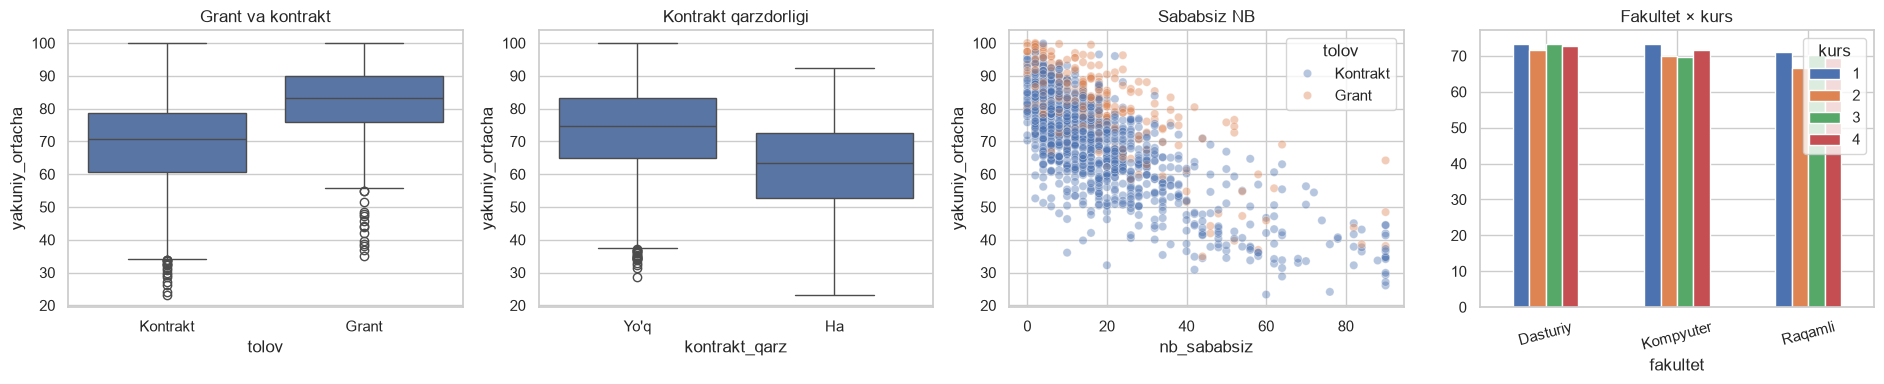

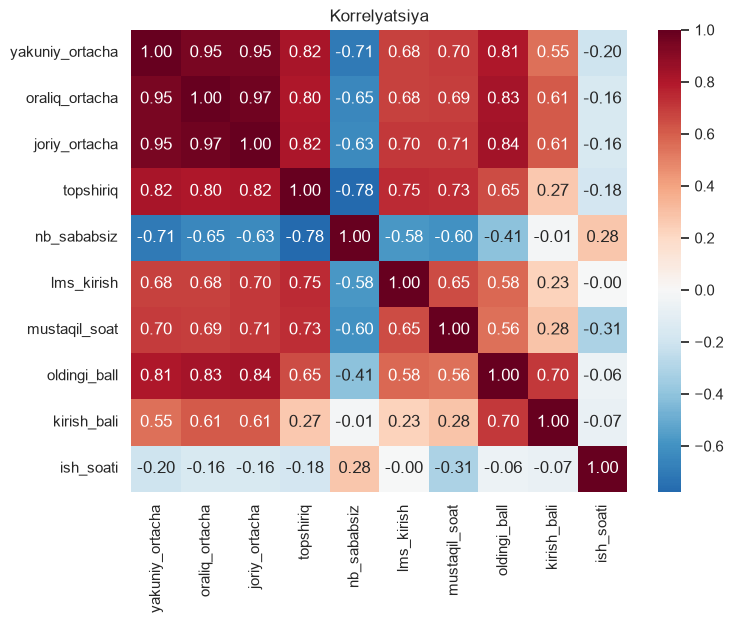

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
sns.boxplot(data=lab, x="tolov", y="yakuniy_ortacha", ax=ax[0]); ax[0].set_title("Grant va kontrakt")
sns.boxplot(data=lab, x="kontrakt_qarz", y="yakuniy_ortacha", ax=ax[1]); ax[1].set_title("Kontrakt qarzdorligi")
sns.scatterplot(data=lab, x="nb_sababsiz", y="yakuniy_ortacha", hue="tolov", alpha=.4, ax=ax[2]); ax[2].set_title("Sababsiz NB")
lab.groupby(["fakultet", "kurs"])["yakuniy_ortacha"].mean().unstack().plot.bar(ax=ax[3], rot=15); ax[3].set_title("Fakultet × kurs")
ax[3].set_xticklabels([t.get_text().split()[0] for t in ax[3].get_xticklabels()])
plt.tight_layout(); plt.show()
corr = lab[["yakuniy_ortacha", "oraliq_ortacha", "joriy_ortacha", "topshiriq", "nb_sababsiz", "lms_kirish", "mustaqil_soat",
            "oldingi_ball", "kirish_bali", "ish_soati"]].corr()
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0); plt.title("Korrelyatsiya"); plt.show()

## 4. Preprocessing pipeline

Barcha modellar bir xil `Pipeline` orqali o'tadi. Bu ma'lumot sizib chiqishining (data leakage) oldini oladi: kross-validatsiyada scaler va imputer faqat o'qitish qismida o'rganiladi.

- **Sonli ustunlar:** bo'sh qiymatlar mediana bilan to'ldiriladi, so'ng standartlashtiriladi.
- **Kategorial ustunlar:** bo'sh qiymatlar eng ko'p uchraydigan qiymat bilan to'ldiriladi, so'ng One-Hot kodlanadi.

In [9]:
def preprocessor(num, cat):
    parts = [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num)]
    if cat: parts.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat))
    return ColumnTransformer(parts)
P = lambda m, num=NUM, cat=CAT: Pipeline([("pre", preprocessor(num, cat)), ("m", m)])
kf = KFold(5, shuffle=True, random_state=SEED)
def reg_row(name, yt, p): return {"model": name, "MAE": mean_absolute_error(yt, p), "RMSE": np.sqrt(np.mean((yt - p) ** 2)), "R2": r2_score(yt, p)}

## 5. Aniqlikni oshirish (1): XGBoost giperparametrlarini sozlash

`RandomizedSearchCV` 16 ta tasodifiy kombinatsiyani 3-fold CV bilan sinaydi va eng kichik MAE beradiganini tanlaydi.

In [10]:
t0 = time.time()
search = RandomizedSearchCV(P(XGBRegressor(random_state=SEED, n_jobs=1)), {
    "m__n_estimators": [200, 300, 400, 600, 800], "m__max_depth": [2, 3, 4, 5, 6], "m__learning_rate": [0.02, 0.03, 0.05, 0.08],
    "m__subsample": [0.7, 0.8, 0.9, 1.0], "m__colsample_bytree": [0.5, 0.7, 0.9], "m__min_child_weight": [1, 3, 5], "m__reg_lambda": [0.5, 1, 3, 10]},
    n_iter=16, scoring="neg_mean_absolute_error", cv=3, random_state=SEED, n_jobs=-1).fit(X, y)
XGB_P = {k.replace("m__", ""): v for k, v in search.best_params_.items()}
default = cross_val_predict(P(XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, random_state=SEED)), X, y, cv=3, n_jobs=-1)
print(f"Standart XGBoost MAE: {mean_absolute_error(y, default):.3f}  →  sozlangan: {-search.best_score_:.3f}  ({time.time()-t0:.0f} s)")
print("Eng yaxshi parametrlar:", XGB_P)

Standart XGBoost MAE: 2.137  →  sozlangan: 2.053  (4 s)
Eng yaxshi parametrlar: {'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.9}


## 6. Regressiya: yakuniy o'rtacha ballni bashorat qilish

Modellarni **bazaviy** yechimlar bilan solishtiramiz. Agar murakkab model "hamma uchun o'rtacha" yoki "faqat oraliq o'rtachasi" dan yaxshi bo'lmasa, uning foydasi yo'q.

**Stacking** — Ridge, XGBoost va HGB bashoratlarini meta-model (RidgeCV) birlashtiradi.

In [11]:
xgb = XGBRegressor(**XGB_P, random_state=SEED, n_jobs=1)
hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED)
REG = {"Ridge regressiya": Ridge(alpha=3.0),
       "Random Forest": RandomForestRegressor(n_estimators=250, min_samples_leaf=2, max_features=0.5, random_state=SEED, n_jobs=1),
       "HistGradientBoosting": hgb, "XGBoost (sozlangan)": xgb,
       "Stacking ansambl": StackingRegressor([("ridge", Ridge(alpha=3.0)), ("xgb", clone(xgb)), ("hgb", clone(hgb))], final_estimator=RidgeCV(), cv=3)}
rows = [reg_row("Bazaviy: o'rtacha qiymat", y, cross_val_predict(DummyRegressor(), X, y, cv=kf)),
        reg_row("Bazaviy: faqat oraliq o'rtachasi", y, cross_val_predict(LinearRegression(), lab[["oraliq_ortacha"]], y, cv=kf))]
preds = {}
for name, m in REG.items():
    preds[name] = cross_val_predict(P(m), X, y, cv=kf, n_jobs=-1); rows.append(reg_row(name, y, preds[name]))
reg_res = pd.DataFrame(rows).round(3); display(reg_res)
BEST_REG = reg_res.iloc[2:].sort_values("MAE").iloc[0]["model"]
SIGMA = float(np.std(y - preds[BEST_REG]))
print(f"Eng yaxshi: {BEST_REG}, qoldiq σ = {SIGMA:.2f}")

,model,MAE,RMSE,R2
0,Bazaviy: o'rtacha qiymat,11.911,14.993,-0.001
1,Bazaviy: faqat oraliq o'rtachasi,3.099,4.639,0.904
2,Ridge regressiya,2.087,3.323,0.951
3,Random Forest,2.260,3.497,0.946
4,HistGradientBoosting,2.130,3.348,0.950
5,XGBoost (sozlangan),2.007,3.186,0.955
6,Stacking ansambl,1.961,3.147,0.956


Eng yaxshi: Stacking ansambl, qoldiq σ = 3.15


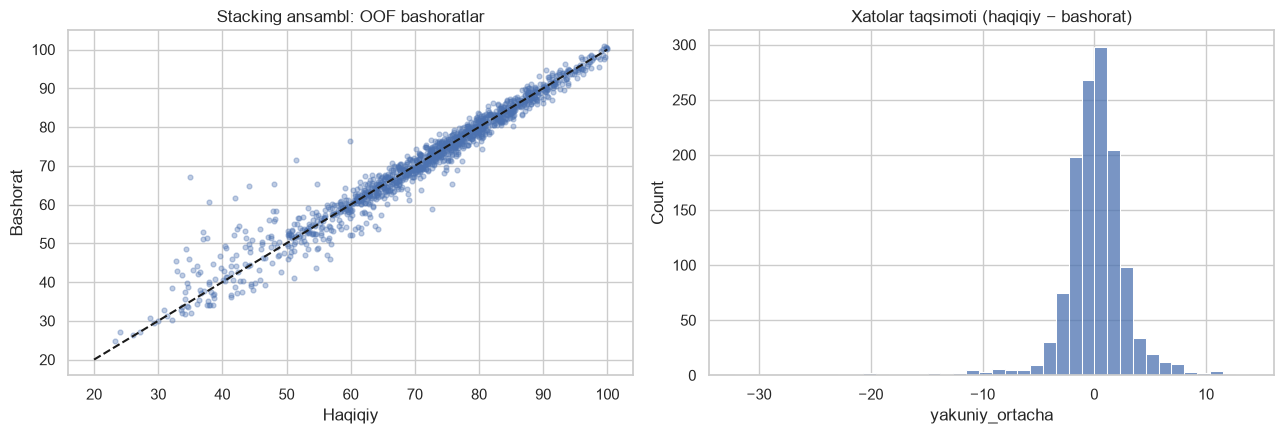

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y, preds[BEST_REG], alpha=.35, s=12); ax[0].plot([20, 100], [20, 100], "k--"); ax[0].set(xlabel="Haqiqiy", ylabel="Bashorat", title=f"{BEST_REG}: OOF bashoratlar")
sns.histplot(y - preds[BEST_REG], bins=40, ax=ax[1]); ax[1].set_title("Xatolar taqsimoti (haqiqiy − bashorat)")
plt.tight_layout(); plt.show()

## 7. Klassifikatsiya

Uchta klassifikatsiya vazifasi bir xil protokolda (stratifikatsiyalangan 5-fold CV) hal qilinadi:
1. **Toifa** (faol baholash tizimi bo'yicha) — metrika: F1 (macro);
2. **O'tadi / o'tmaydi** — kamida bitta fandan qarz; metrikalar: ROC-AUC va Recall (xavfli talabani o'tkazib yubormaslik muhim);
3. **Chetlashtirish xavfi** — 3 va undan ortiq fandan qarz.

── Toifalar: eng yaxshi — Soft-voting ansambl


,model,Accuracy,F1 (macro)
0,Bazaviy: oraliq bo'yicha toifa,0.823,0.802
1,Logistik regressiya,0.865,0.863
2,Random Forest,0.876,0.874
3,HistGradientBoosting,0.888,0.883
4,XGBoost,0.882,0.881
5,Soft-voting ansambl,0.888,0.886


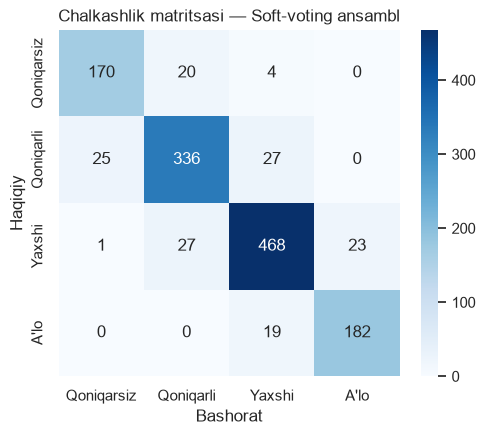

In [13]:
def CLF():
    lr = LogisticRegression(max_iter=4000, C=0.5, class_weight="balanced")
    rf = RandomForestClassifier(n_estimators=250, min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=1)
    xg = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.85, colsample_bytree=0.8, random_state=SEED, n_jobs=1)
    return {"Logistik regressiya": lr, "Random Forest": rf,
            "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=250, learning_rate=0.05, class_weight="balanced", random_state=SEED),
            "XGBoost": xg, "Soft-voting ansambl": VotingClassifier([("lr", clone(lr)), ("rf", clone(rf)), ("xgb", clone(xg))], voting="soft")}

def run_clf(target, baseline, title):
    skf = StratifiedKFold(5, shuffle=True, random_state=SEED); binary = target.nunique() == 2
    def row(name, pred, proba=None):
        r = {"model": name, "Accuracy": accuracy_score(target, pred), "F1 (macro)": f1_score(target, pred, average="macro")}
        if binary: r.update(Recall=recall_score(target, pred), **{"ROC-AUC": roc_auc_score(target, proba[:, 1] if proba is not None else pred)})
        return r
    rows, probs = [row(baseline[0], baseline[1])], {}
    for name, m in CLF().items():
        probs[name] = cross_val_predict(P(m), X, target, cv=skf, method="predict_proba", n_jobs=-1)
        rows.append(row(name, probs[name].argmax(1), probs[name]))
    res = pd.DataFrame(rows).round(3); key = "ROC-AUC" if binary else "F1 (macro)"
    best = res.iloc[1:].sort_values(key, ascending=False).iloc[0]["model"]
    print(f"── {title}: eng yaxshi — {best}"); display(res)
    return best, probs[best], res

y_cat = y.map(toifa_idx)
best_cat, p_cat, res_cat = run_clf(y_cat, ("Bazaviy: oraliq bo'yicha toifa", lab["oraliq_ortacha"].map(toifa_idx)), "Toifalar")
cm = confusion_matrix(y_cat, p_cat.argmax(1))
plt.figure(figsize=(5.5, 4.5)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=TOIFA, yticklabels=TOIFA)
plt.xlabel("Bashorat"); plt.ylabel("Haqiqiy"); plt.title(f"Chalkashlik matritsasi — {best_cat}"); plt.show()

Qarzdorlar ulushi: 24.1%, chetlashtirish xavfi ostidagilar: 15.8%


── O'tadi / o'tmaydi: eng yaxshi — Soft-voting ansambl


,model,Accuracy,F1 (macro),Recall,ROC-AUC
0,Bazaviy: oraliqda o'tmagan fan bor,0.919,0.884,0.774,0.869
1,Logistik regressiya,0.932,0.911,0.920,0.982
2,Random Forest,0.932,0.910,0.911,0.980
3,HistGradientBoosting,0.941,0.918,0.863,0.977
4,XGBoost,0.938,0.914,0.850,0.978
5,Soft-voting ansambl,0.939,0.918,0.889,0.983


── Chetlashtirish xavfi: eng yaxshi — HistGradientBoosting


,model,Accuracy,F1 (macro),Recall,ROC-AUC
0,Bazaviy: oraliqda 3+ o'tmagan fan,0.921,0.820,0.544,0.768
1,Logistik regressiya,0.942,0.899,0.913,0.985
2,Random Forest,0.944,0.902,0.913,0.986
3,HistGradientBoosting,0.955,0.917,0.883,0.990
4,XGBoost,0.953,0.911,0.835,0.989
5,Soft-voting ansambl,0.953,0.915,0.893,0.988


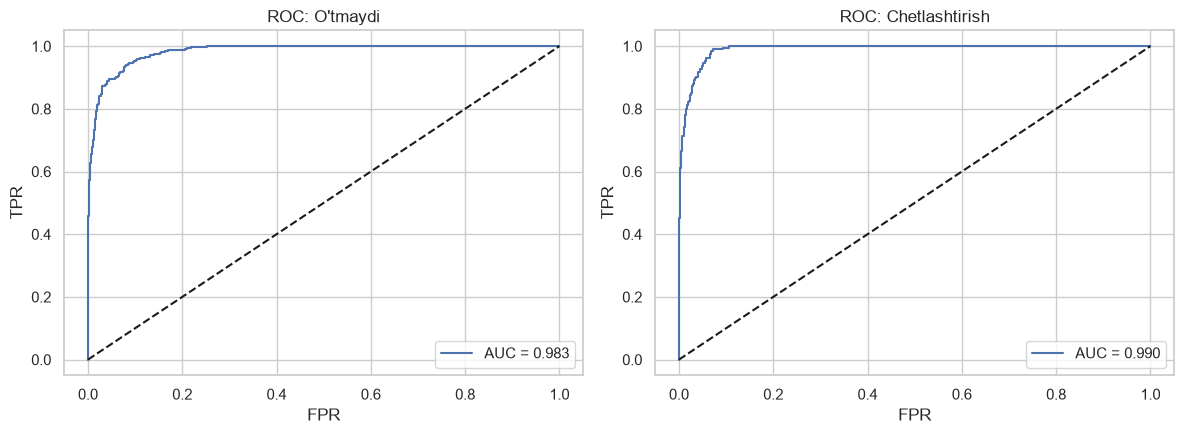

In [14]:
y_fail = (lab["qarz_soni"] > 0).astype(int); y_chet = (lab["qarz_soni"] >= 3).astype(int)
print(f"Qarzdorlar ulushi: {y_fail.mean():.1%}, chetlashtirish xavfi ostidagilar: {y_chet.mean():.1%}")
best_fail, p_fail, res_fail = run_clf(y_fail, ("Bazaviy: oraliqda o'tmagan fan bor", (lab["past_fanlar"] > 0).astype(int)), "O'tadi / o'tmaydi")
best_chet, p_chet, res_chet = run_clf(y_chet, ("Bazaviy: oraliqda 3+ o'tmagan fan", (lab["past_fanlar"] >= 3).astype(int)), "Chetlashtirish xavfi")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, yt, p, t in ((ax[0], y_fail, p_fail, "O'tmaydi"), (ax[1], y_chet, p_chet, "Chetlashtirish")):
    fpr, tpr, _ = roc_curve(yt, p[:, 1]); a.plot(fpr, tpr, label=f"AUC = {roc_auc_score(yt, p[:, 1]):.3f}"); a.plot([0, 1], [0, 1], "k--")
    a.set(title=f"ROC: {t}", xlabel="FPR", ylabel="TPR"); a.legend()
plt.tight_layout(); plt.show()

## 8. Fan darajasidagi model (talaba × fan)

Talaba darajasidagi model butun semestr natijasini beradi. Dekanatga esa **qaysi fandan** qarz bo'lishi muhim. Shuning uchun har bir "talaba × fan" qatori uchun alohida model quriladi:

- talaba belgilariga shu fanning joriy va oraliq bali qo'shiladi;
- fan qiyinligi (silliqlangan o'rtacha) va kredit ham belgi sifatida beriladi;
- **GroupKFold** ishlatiladi: bir talabaning fanlari bir vaqtda ham o'qitishda, ham testda bo'lmaydi (sizib chiqish yo'q);
- qarz ehtimoli = Φ((o'tish chegarasi − bashorat) / σ).

Bu yondashuv yangi fan qo'shilganda ham ishlaydi: fanlar soni modelga ta'sir qilmaydi.

,model,MAE,RMSE,R2
0,Bazaviy: fan oraliq + joriy,4.209,6.171,0.852
1,XGBoost (fan darajasi),3.660,5.178,0.896


7812 ta qator · σ = 5.18 · fan bo'yicha qarz ROC-AUC = 0.977


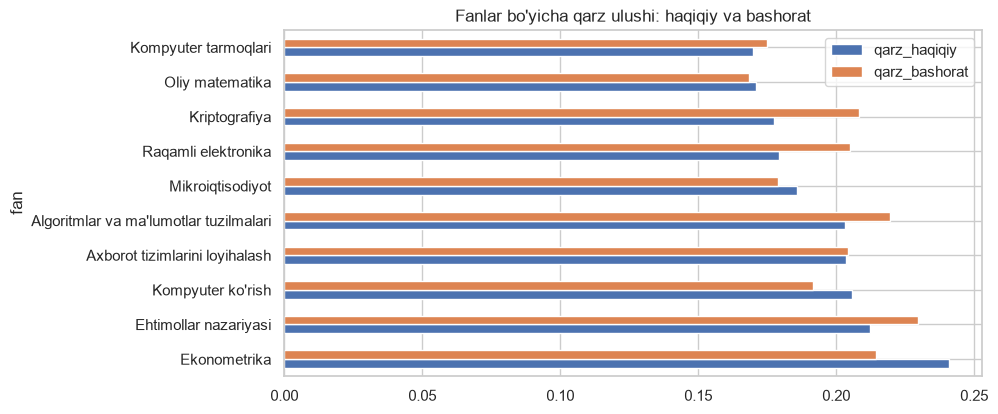

In [15]:
gm = g["oraliq"].mean(); n = g.groupby("fan_id").size()
qiy = ((g.groupby("fan_id")["oraliq"].mean() - gm) * n / (n + 20))
F = g.merge(lab[["talaba_id"] + NUM_BASE + CAT + AGG + ENG], on="talaba_id")
F = F[F["yakuniy"].notna()].reset_index(drop=True)
F["fan_qiyinlik"] = F["fan_id"].map(qiy); F["oraliq_vs_ortacha"] = F["oraliq"] - F["oraliq_ortacha"]
SUBJ = ["joriy", "oraliq", "fan_qiyinlik", "oraliq_vs_ortacha", "kredit"]
gkf = GroupKFold(5)
ps = cross_val_predict(P(XGBRegressor(**XGB_P, random_state=SEED, n_jobs=1), NUM + SUBJ, CAT), F[NUM + CAT + SUBJ], F["yakuniy"], cv=gkf, groups=F["talaba_id"], n_jobs=-1)
base = cross_val_predict(LinearRegression(), F[["oraliq", "joriy"]], F["yakuniy"], cv=gkf, groups=F["talaba_id"])
display(pd.DataFrame([reg_row("Bazaviy: fan oraliq + joriy", F["yakuniy"], base), reg_row("XGBoost (fan darajasi)", F["yakuniy"], ps)]).round(3))
sig_s = np.std(F["yakuniy"] - ps); fail_true = (F["yakuniy"] < F["pass_min"]).astype(int); fail_p = norm.cdf((F["pass_min"] - ps) / sig_s)
print(f"{len(F)} ta qator · σ = {sig_s:.2f} · fan bo'yicha qarz ROC-AUC = {roc_auc_score(fail_true, fail_p):.3f}")
per_fan = F.assign(pred=ps, fp=fail_p, ft=fail_true).groupby("fan").agg(n=("pred", "size"), qarz_haqiqiy=("ft", "mean"), qarz_bashorat=("fp", "mean"))
per_fan.sort_values("qarz_haqiqiy", ascending=False).head(10).plot.barh(y=["qarz_haqiqiy", "qarz_bashorat"], figsize=(9, 4.5), title="Fanlar bo'yicha qarz ulushi: haqiqiy va bashorat"); plt.show()

## 9. Aniqlikni oshirish (2): belgilar ta'siri va ma'lumot hajmi

- **Ablation:** belgilar guruhlari bosqichma-bosqich qo'shiladi. Har guruh aniqlikka qancha hissa qo'shayotgani ko'rinadi.
- **Learning curve:** talabalar soni ortgani sari xato qanday kamayishi. **100 ta talaba kam**: 1000+ talabada model ancha aniqroq.

,belgilar,MAE,R2
0,Faqat baholar,2.939,0.909
1,+ davomat va faollik,2.624,0.935
2,+ ijtimoiy-iqtisodiy,2.012,0.954
3,+ hosila belgilar (to'liq),2.007,0.955


,talabalar,MAE
0,50,3.157
1,100,2.965
2,200,2.611
3,400,2.304
4,700,2.126
5,1042,2.011


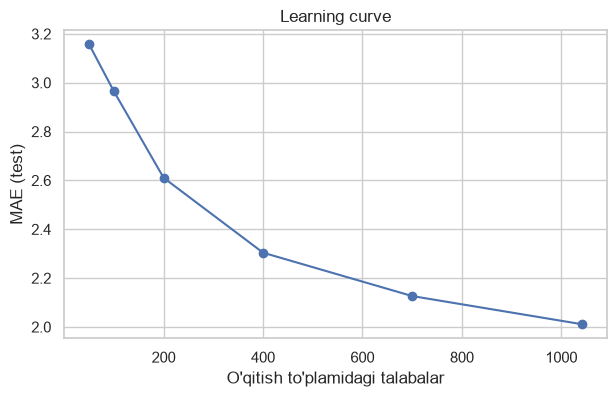

In [16]:
X_ = lambda: XGBRegressor(**XGB_P, random_state=SEED, n_jobs=1)
act = ["nb_sababli", "nb_sababsiz", "topshiriq", "lms_kirish", "kutubxona", "mustaqil_soat"]
abl = []
for name, num, cat in (("Faqat baholar", AGG, []), ("+ davomat va faollik", AGG + act, []),
                       ("+ ijtimoiy-iqtisodiy", NUM_BASE + AGG, CAT), ("+ hosila belgilar (to'liq)", NUM, CAT)):
    p = cross_val_predict(P(X_(), num, cat), lab[num + cat], y, cv=kf, n_jobs=-1); abl.append({"belgilar": name, "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)})
display(pd.DataFrame(abl).round(3))
rng = np.random.default_rng(SEED); perm = rng.permutation(len(lab)); test, pool = perm[: len(lab) // 5], perm[len(lab) // 5:]
lc = []
for n_ in [50, 100, 200, 400, 700, len(pool)]:
    maes = [mean_absolute_error(y.iloc[test], P(X_()).fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[test]))
            for tr in ([rng.choice(pool, n_, replace=False) for _ in range(3)] if n_ < len(pool) else [pool])]
    lc.append({"talabalar": n_, "MAE": np.mean(maes)})
lc = pd.DataFrame(lc); display(lc.round(3))
plt.figure(figsize=(7, 4)); plt.plot(lc["talabalar"], lc["MAE"], "o-"); plt.xlabel("O'qitish to'plamidagi talabalar"); plt.ylabel("MAE (test)"); plt.title("Learning curve"); plt.show()

## 10. Klasterlash: o'xshash talabalar guruhlari

K-Means 6 ta belgi bo'yicha ishlaydi: oraliq o'rtachasi, sababsiz NB, topshiriqlar, LMS faolligi, oldingi ball va mustaqil ta'lim. NB va LMS taqsimoti qiyshiq bo'lgani uchun log1p qo'llanadi.

Klasterlar soni silhouette tahlili va talqin qulayligi asosida tanlanadi. Har klasterga markazidagi (z-ball) ikki o'q bo'yicha nom beriladi:
- **natija o'qi** = oraliq + 0.5 × oldingi ball;
- **faollik o'qi** = topshiriq + LMS + mustaqil ta'lim − NB.

Masalan, faollik natijadan sezilarli yuqori bo'lsa — **"Faol, lekin bahosi past"**.

Silhouette: k=2: 0.383, k=3: 0.287, k=4: 0.233, k=5: 0.224, k=6: 0.199, k=7: 0.192


,oraliq_ortacha,nb_sababsiz,topshiriq,lms_kirish,oldingi_ball,mustaqil_soat,yakuniy_ortacha,n
klaster_nomi,,,,,,,,
A'lochi va faol,87.8,4.8,91.1,35.7,81.4,13.4,88.3,266
"Qobiliyatli, lekin intizomi past",80.6,16.5,73.1,19.8,78.0,7.5,79.9,328
"Faol, lekin bahosi past",73.2,7.5,77.8,22.5,65.0,8.6,72.5,293
"O'rtacha, sust",66.4,24.6,49.8,13.3,62.6,4.2,63.0,423
Xavf guruhi,52.3,47.5,25.0,8.2,49.3,0.9,44.7,190


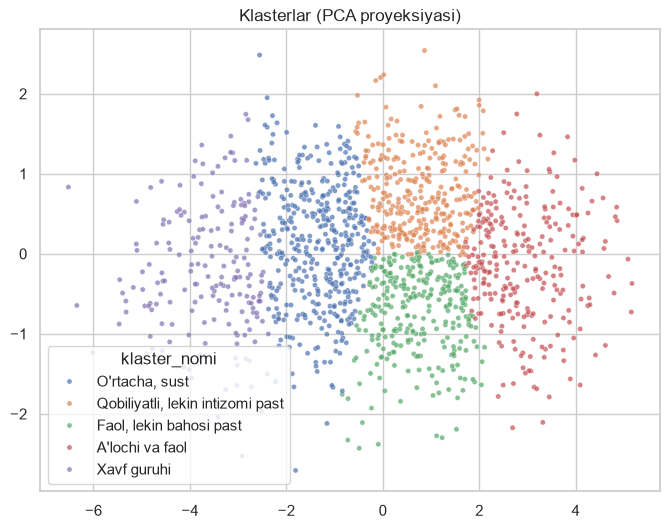

In [17]:
CF = ["oraliq_ortacha", "nb_sababsiz", "topshiriq", "lms_kirish", "oldingi_ball", "mustaqil_soat"]
C = S[CF].astype(float).copy(); C["nb_sababsiz"] = np.log1p(C["nb_sababsiz"]); C["lms_kirish"] = np.log1p(C["lms_kirish"]); C = C.fillna(C.median())
sc = StandardScaler().fit(C); Z = sc.transform(C)
ks = [(k, silhouette_score(Z, KMeans(k, n_init=10, random_state=SEED).fit_predict(Z))) for k in range(2, 8)]
print("Silhouette:", ", ".join(f"k={k}: {s:.3f}" for k, s in ks))
K = 5
km = KMeans(K, n_init=20, random_state=SEED).fit(Z); S["klaster"] = km.labels_
cen = pd.DataFrame(km.cluster_centers_, columns=CF)
score = (cen["oraliq_ortacha"] + 0.5 * cen["oldingi_ball"]) / 1.5
actv = (cen["topshiriq"] + 0.5 * cen["lms_kirish"] + 0.5 * cen["mustaqil_soat"] - cen["nb_sababsiz"]) / 2.5
tot = score + actv; names, left = {}, set(range(K))
top = int(tot.idxmax()); names[top] = "A'lochi va faol"; left.discard(top)
low = int(tot.loc[list(left)].idxmin()); names[low] = "Xavf guruhi"; left.discard(low)
for k in left:
    d = actv[k] - score[k]
    names[k] = "Faol, lekin bahosi past" if d > .3 else "Qobiliyatli, lekin intizomi past" if d < -.3 else "Yaxshi, barqaror" if tot[k] > 0 else "O'rtacha, sust"
S["klaster_nomi"] = S["klaster"].map(names)
display(S.groupby("klaster_nomi")[CF + ["yakuniy_ortacha"]].mean().round(1).assign(n=S["klaster_nomi"].value_counts()).sort_values("yakuniy_ortacha", ascending=False))
xy = PCA(2, random_state=SEED).fit_transform(Z)
plt.figure(figsize=(8, 6)); sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=S["klaster_nomi"], s=14, alpha=.7); plt.title("Klasterlar (PCA proyeksiyasi)"); plt.show()

## 11. Anomaliyalarni aniqlash (Isolation Forest)

Ko'rsatkichlari g'ayrioddiy kombinatsiyadagi talabalar topiladi (masalan, NB juda ko'p, lekin baholar juda yuqori). Bu kiritishdagi xato yoki alohida e'tibor talab qiladigan holat bo'lishi mumkin.

In [18]:
iso_pre = preprocessor(NUM, []); A = iso_pre.fit_transform(S[NUM])
iso = IsolationForest(n_estimators=300, contamination=0.04, random_state=SEED).fit(A)
S["anomaliya"] = iso.predict(A) == -1
print(f"G'ayrioddiy profillar: {S['anomaliya'].sum()} ta")
S[S["anomaliya"]][["fio", "guruh", "oraliq_ortacha", "nb_sababsiz", "topshiriq", "yakuniy_ortacha"]].head(10)

G'ayrioddiy profillar: 60 ta


,fio,guruh,oraliq_ortacha,nb_sababsiz,topshiriq,yakuniy_ortacha
27,Zokirov Shoxjahon,AX23-1,42.833333,34.0,25.0,35.363636
106,Abdullayeva Nilufar,SI24-2,46.500000,82.0,16.0,37.870968
107,Haydarova Shohista,RI23-1,56.000000,62.0,14.0,43.233333
116,Tursunova Durdona,AT25-2,42.500000,82.0,11.0,32.206897
133,Ismoilova Malika,KI25-1,99.000000,0.0,98.0,100.000000
139,Bozorov Shohruh,AT25-2,42.833333,42.0,13.0,30.862069
145,Fayzullayeva Nilufar,RI26-2,40.166667,90.0,10.0,34.620690
162,Toshpo'latov Behruz,SI24-1,56.166667,58.0,23.0,36.161290
170,Yusupov Akmal,RI24-2,46.166667,66.0,25.0,NaN
173,Musayev Alisher,RI26-2,46.166667,74.0,12.0,45.896552


## 12. Model qarorlarini izohlash (SHAP)

SHAP har bir belgi bashoratni o'rtacha qiymatdan qanchaga oshirgan yoki kamaytirganini ko'rsatadi:
- **global** — butun model uchun eng muhim omillar;
- **lokal** — bitta talaba uchun "nega bunday ball chiqdi".

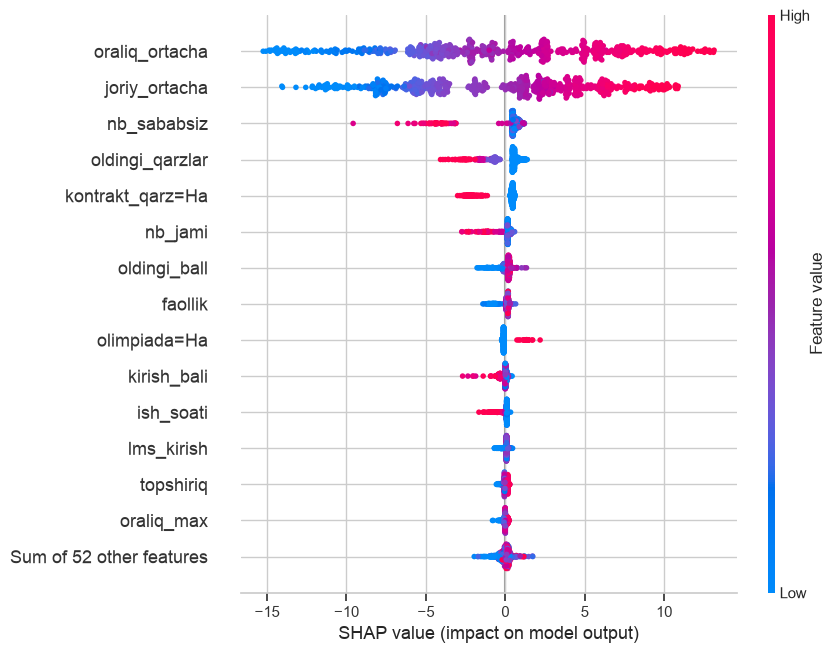

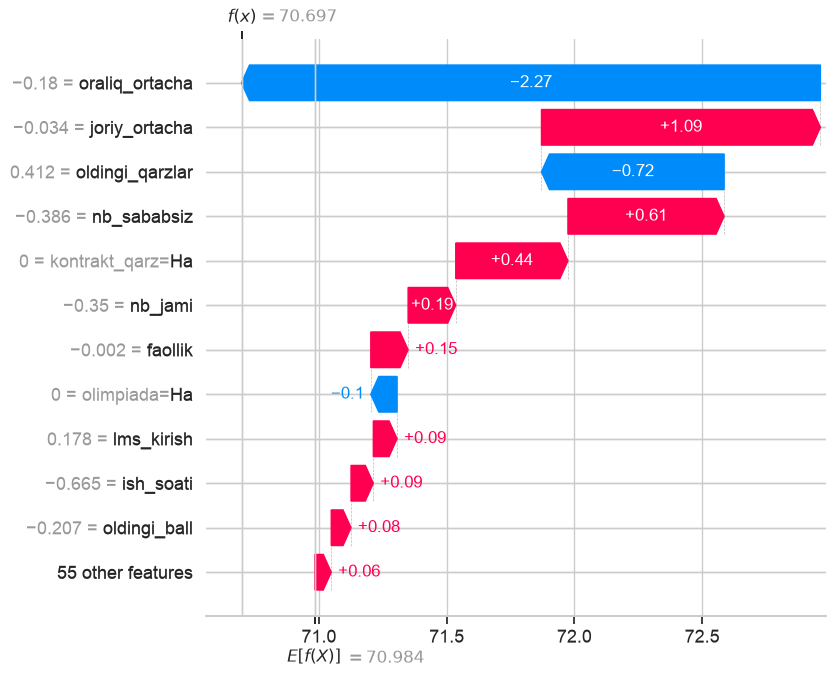

In [19]:
ex_pipe = P(XGBRegressor(**XGB_P, random_state=SEED)).fit(X, y)
pre = ex_pipe.named_steps["pre"]; oh = pre.named_transformers_["cat"].named_steps["oh"]
fn = NUM + [f"{c}={v}" for c, cats in zip(CAT, oh.categories_) for v in cats]
Xt = pre.transform(X.sample(600, random_state=SEED))
explainer = shap.TreeExplainer(ex_pipe.named_steps["m"]); sv = explainer(Xt); sv.feature_names = fn
shap.plots.beeswarm(sv, max_display=15)
shap.plots.waterfall(sv[0], max_display=12)

## 13. Yangi talaba uchun bashorat

Web tizimdagi "+ Yangi talaba" formasi aynan shu ishni bajaradi: yakuniy hali ma'lum bo'lmagan talabalar uchun barcha modellar ishga tushadi.

In [20]:
final = {"reg": P(REG[BEST_REG]).fit(X, y), "cat": P(CLF()[best_cat]).fit(X, y_cat),
         "fail": P(CLF()[best_fail]).fit(X, y_fail), "chet": P(CLF()[best_chet]).fit(X, y_chet)}
yangi = S[S["yakuniy_ortacha"].isna()].head(8).copy()
yangi["bashorat_ball"] = final["reg"].predict(yangi[NUM + CAT]).clip(0, 100).round(1)
yangi["toifa"] = [TOIFA[i] for i in final["cat"].predict(yangi[NUM + CAT])]
yangi["qarz_ehtimoli"] = final["fail"].predict_proba(yangi[NUM + CAT])[:, 1].round(2)
yangi["chetlash_xavfi"] = final["chet"].predict_proba(yangi[NUM + CAT])[:, 1].round(2)
yangi["alo_ehtimoli"] = norm.cdf((yangi["bashorat_ball"] - 86) / SIGMA).round(2)
yangi[["fio", "guruh", "tolov", "oraliq_ortacha", "nb_sababsiz", "bashorat_ball", "toifa", "qarz_ehtimoli", "chetlash_xavfi", "alo_ehtimoli", "klaster_nomi"]]

,fio,guruh,tolov,oraliq_ortacha,nb_sababsiz,bashorat_ball,toifa,qarz_ehtimoli,chetlash_xavfi,alo_ehtimoli,klaster_nomi
8,Raximberdiyeva Sevara,RI26-1,Kontrakt,64.833333,6.0,64.4,Qoniqarli,0.24,0.00,0.00,"Faol, lekin bahosi past"
20,Nazarov Nodirbek,SI24-1,Kontrakt,62.333333,28.0,60.6,Qoniqarli,0.56,0.01,0.00,"O'rtacha, sust"
21,Ortiqov Jasur,DI26-1,Kontrakt,81.666667,4.0,80.6,Yaxshi,0.01,0.00,0.04,"Faol, lekin bahosi past"
23,Bakirov Bobur,RI23-1,Kontrakt,78.666667,6.0,76.5,Yaxshi,0.00,0.00,0.00,"Faol, lekin bahosi past"
32,Yo'ldoshev Kamron,KI26-2,Kontrakt,49.333333,34.0,48.4,Qoniqarsiz,0.99,1.00,0.00,Xavf guruhi
33,Xolmatova Aziza,AT24-1,Kontrakt,79.666667,12.0,81.3,Yaxshi,0.00,0.00,0.07,"Qobiliyatli, lekin intizomi past"
38,Bozorov Behruz,DI23-2,Kontrakt,66.166667,10.0,64.6,Qoniqarli,0.34,0.00,0.00,"O'rtacha, sust"
59,Sharipov Ulug'bek,DI25-2,Kontrakt,52.666667,32.0,48.5,Qoniqarsiz,1.00,1.00,0.00,Xavf guruhi


## 14. Xulosa

1. **Regressiya:** ansambl usullari yakuniy o'rtacha ballni ~2 ball xato bilan bashorat qiladi (R² ≈ 0.95). Bu "faqat oraliq" bazaviy yechimidan sezilarli aniqroq.
2. **Klassifikatsiya:** toifalar F1 ≈ 0.88. Akademik qarz ROC-AUC ≈ 0.98, chetlashtirish xavfi ROC-AUC ≈ 0.99.
3. **Fan darajasidagi model** qaysi fandan qarz bo'lishini oldindan ko'rsatadi (AUC ≈ 0.98).
4. **Aniqlikni oshirish:**
   - giperparametrlarni sozlash;
   - hosila belgilar;
   - ansambllar;
   - eng muhimi — **ma'lumot hajmi**: 100 → 1000+ talabaga o'tganda xato ~1 ballga kamaydi.
5. **Klasterlash** talabalarni 5 ta mazmunli guruhga ajratadi: "Xavf guruhi", "Faol, lekin bahosi past" va boshqalar. Har bir guruh uchun turli pedagogik choralar kerak.
6. Eng kuchli omillar: **joriy va oraliq nazorat, topshiriqlar, sababsiz NB, LMS faolligi, kontrakt qarzdorligi**.

Barcha modellar web tizimga ulangan: talaba qo'shilganda yoki o'zgartirilganda avtomatik qayta o'qitiladi.